# Problem 10 · Developing laminar flow in a channel

**simple_CFD · Introduction to Computational Fluid Dynamics with the Finite Difference Method**

> *A fluid enters the gap between two long parallel plates with a uniform velocity $U$. Friction at the walls slows the fluid down there, so it must speed up in the middle, until far downstream the velocity profile no longer changes: the parabola of plane Poiseuille flow. Find the developing velocity field, the **entrance length** and the **pressure drop** at Reynolds numbers 50 and 100, and check them against the exact fully developed solution and a published correlation.*

Problems 6 and 7 solved the Navier–Stokes equations in a **closed box** with the stream function and the vorticity, so the pressure never appeared. Here the fluid **flows through** the domain: it enters at an inlet and leaves at an outlet, and the quantity we want, the pressure drop, is the pressure itself. So we solve for the **primitive variables** $u$, $v$ and $p$ directly, with the method behind most incompressible flow solvers: the **projection method** on a **staggered grid**.

In this notebook we solve the problem **step by step, following the 7 pillars of CFD**:

| Pillar | What we do here |
|:-:|---|
| 1 · Geometry | describe the channel, the Reynolds number and a real example |
| 2 · Grid | a **staggered (MAC) grid**: pressure in the cells, velocities on the faces |
| 3 · Physics | the Navier–Stokes equations in $u$, $v$, $p$; inlet, outlet and wall conditions; the exact fully developed solution |
| 4 · Numerical scheme | the **projection method**: predictor, **pressure Poisson equation**, correction |
| 5 · Solution setup | the stable time step, SOR with a block correction, the steady-state test |
| 6 · Compute | march in time to the steady state for $Re = 50$ and $100$ |
| 7 · Post-processing | velocity field, profiles, entrance length, mass conservation, pressure drop, the checkerboard, grid study |

> **Plain Python only.** All numerical work uses ordinary Python lists and `for` loops, so you can follow every number. The only imports used in the calculations are `math` and `time` (both part of Python itself). The figures are drawn by `plots.py` (with matplotlib); you do not need to open it to follow the method.

In [1]:
import math     # built into Python
import time     # built into Python: measure the run time
import plots    # our drawing helpers (plots.py)

---
## Pillar 1 · The physical problem and its geometry

Two parallel plates, a distance $H$ apart, form a long channel. A fluid enters at $x = 0$ with the same velocity $U$ everywhere across the gap (a "plug" profile) and leaves at $x = L$ into a large space where the pressure is $p = 0$ (we measure pressures relative to the outlet).

At the walls the fluid sticks (no slip). A thin **boundary layer** of slow fluid forms on each plate and grows downstream. Because the same amount of fluid has to pass every cross-section, the fluid in the middle must **speed up**. Once the two boundary layers meet in the middle, the profile stops changing: the flow is **fully developed**. The distance it takes is the **entrance length** $L_e$.

**Dimensionless form.** We measure lengths in units of $H$, velocities in units of $U$, time in units of $H/U$ and pressure in units of $\rho U^2$. One number remains, the **Reynolds number**

$$Re = \frac{\rho\,U\,H}{\mu} = \frac{U\,H}{\nu},$$

the ratio of inertia to viscous friction. We solve $Re = 50$ and $Re = 100$, in a channel $L = 10\,H$ long. What these numbers mean for a real flow:

In [2]:
Re_values = [50, 100]          # the two Reynolds numbers of the problem
length = 10.0                  # channel length L in units of H

# a real example: water in a 1 mm gap, as in a compact plate heat exchanger or a microfluidic chip
rho, mu = 998.0, 1.0e-3        # density [kg/m^3] and viscosity [Pa s] of water at 20 °C
H_gap = 1.0e-3                 # gap between the plates [m]
for Re in Re_values:
    U = Re * mu / (rho * H_gap)
    print(f"Re = {Re:3d}: water in a {H_gap * 1000:.0f} mm gap, mean velocity U = {U * 100:.1f} cm/s")

Re =  50: water in a 1 mm gap, mean velocity U = 5.0 cm/s
Re = 100: water in a 1 mm gap, mean velocity U = 10.0 cm/s


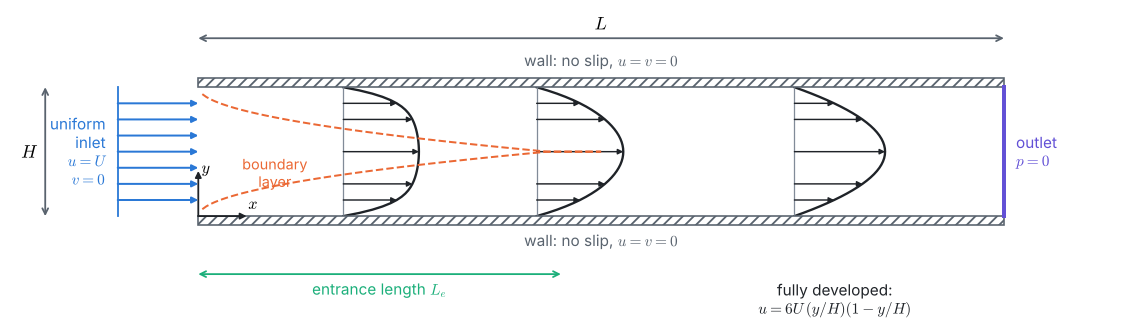

In [3]:
plots.schematic()

---
## Pillar 2 · The grid: a staggered (MAC) grid

We cover the channel with square cells of side $h = H/16$: $16$ cells across and $160$ along the channel. On this grid we need three unknowns, $u$, $v$ and $p$. **Where** we store them matters a lot.

The obvious choice, all three at the same points (a **collocated** grid), has a hidden flaw: the central difference for the pressure gradient at a node, $(p_E - p_W)/(2h)$, skips the node itself. A pressure that zig-zags from node to node, a **checkerboard**, then has a zero gradient everywhere and is invisible to the momentum equations: the solver cannot tell it from a smooth pressure, and checkerboard wiggles appear in the result. (We demonstrate this with numbers in Pillar 7.)

The cure, invented by Harlow and Welch (1965) for the *Marker-And-Cell* (MAC) method, is the **staggered grid**:

* the **pressure** $p$ lives at the **centre** of each cell;
* the velocity $u$ lives on the **vertical faces** (the left and right sides of a cell);
* the velocity $v$ lives on the **horizontal faces** (the top and bottom of a cell).

Now the pressure difference that pushes the fluid through a face uses the two cells on either side of that face, $(p_E - p_P)/h$: neighbouring values, no gaps, and a checkerboard would produce the largest possible push. And the flow out of a cell is simply what crosses its four faces.

**Indices.** Cells are numbered $i = 1 \dots n_x$ along the channel and $j = 1 \dots n_y$ across it. In the code `p[j][i]` is the pressure of cell $(i, j)$, `u[j][i]` the velocity on the **right** face of cell $(i, j)$ (so `u[j][0]` is the inlet and `u[j][nx]` the outlet), and `v[j][i]` the velocity on the **top** face of cell $(i, j)$ (so `v[0][i]` and `v[ny][i]` lie on the walls). One extra row or column of **ghost values** around the domain (the grey arrows below) carries the boundary conditions, like the ghost nodes of Problems 1 and 7.

In [4]:
ny = 16                        # cells across the channel
h = 1 / ny                     # cell size (in units of H)
nx = round(length / h)         # cells along the channel

print(f"h = {h} H:  {nx} x {ny} cells")
print(f"unknowns: p {nx * ny},  u {(nx - 1) * ny} (+ {ny} on the outlet),  v {nx * (ny - 1)}")

h = 0.0625 H:  160 x 16 cells
unknowns: p 2560,  u 2544 (+ 16 on the outlet),  v 2400


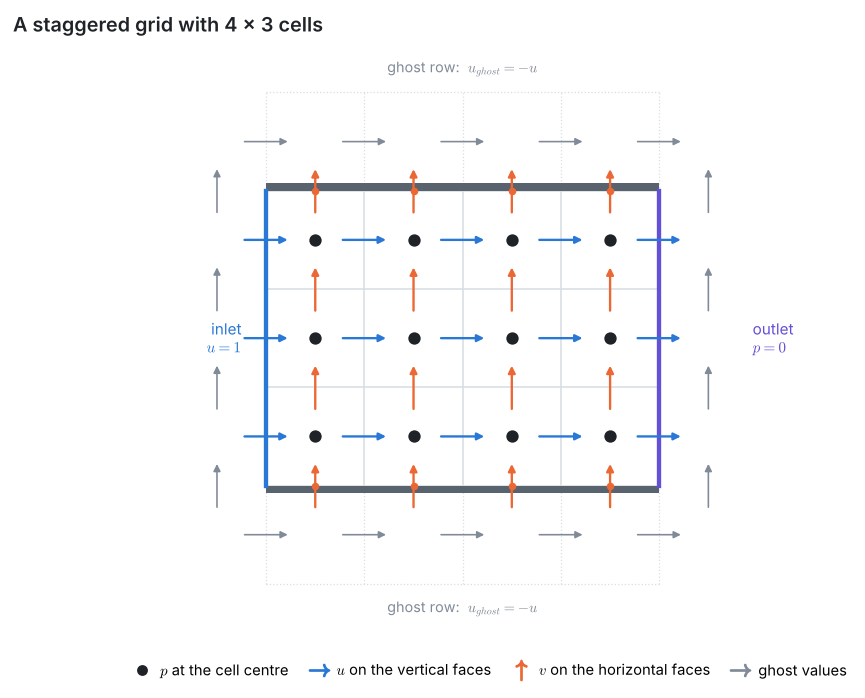

In [5]:
plots.grid(4, 3, "A staggered grid with 4 × 3 cells")

---
## Pillar 3 · Physics: the Navier–Stokes equations in primitive variables

Steady or not, an incompressible flow obeys conservation of **mass** (continuity) and of **momentum**. In dimensionless form:

$$\frac{\partial u}{\partial x} + \frac{\partial v}{\partial y} = 0,$$

$$\frac{\partial u}{\partial t} + u\,\frac{\partial u}{\partial x} + v\,\frac{\partial u}{\partial y} = -\frac{\partial p}{\partial x} + \frac{1}{Re}\left(\frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2}\right),$$

$$\frac{\partial v}{\partial t} + u\,\frac{\partial v}{\partial x} + v\,\frac{\partial v}{\partial y} = -\frac{\partial p}{\partial y} + \frac{1}{Re}\left(\frac{\partial^2 v}{\partial x^2} + \frac{\partial^2 v}{\partial y^2}\right).$$

**The role of the pressure.** There is no equation "for $p$". The pressure is whatever it has to be so that the velocity stays **divergence-free** (mass is conserved). The projection method in Pillar 4 turns this idea into an algorithm.

**Boundary conditions.** Problems 6 and 7 had only walls. A channel has three kinds of boundary:

| Boundary | Velocity | Pressure |
|---|---|---|
| inlet, $x = 0$ | $u = 1$, $v = 0$ (uniform plug) | not prescribed: $\partial p/\partial x = 0$ in the pressure equation |
| walls, $y = 0$ and $y = 1$ | no slip: $u = v = 0$ | not prescribed: $\partial p/\partial y = 0$ |
| outlet, $x = L$ | not prescribed: $\partial u/\partial x = \partial v/\partial x = 0$ | $p = 0$ |

Notice the pattern: **where the velocity is given, the pressure is free, and where the pressure is given, the velocity is free.** Prescribing both at the same boundary would over-determine the problem. The outlet must be far enough downstream that the flow there has stopped changing, so that $\partial u/\partial x = 0$ is true.

**The exact fully developed solution.** Far downstream $v = 0$ and $u$ depends on $y$ only. Then continuity is satisfied, the convection terms vanish and the $x$-momentum equation becomes $dp/dx = (1/Re)\,d^2u/dy^2$ with a constant pressure gradient. With $u = 0$ on both walls and a flow rate $\int_0^1 u\,dy = 1$ (mass conservation: what enters must pass):

$$u(y) = 6\,y\,(1 - y), \qquad u_{max} = u(0.5) = 1.5, \qquad \frac{dp}{dx} = -\frac{12}{Re}.$$

In dimensional form, $u = 6U\,(y/H)(1 - y/H)$ and $dp/dx = -12\,\mu\,U/H^2$: plane **Poiseuille flow**.

**The entrance length** is defined as the distance at which the centre-line velocity reaches **99 %** of its fully developed value. Durst, Ray, Ünsal and Bayoumi (*J. Fluids Eng.* 127, 2005, 1154–1160) computed developing channel flows with a uniform inlet for a wide range of $Re$ and fitted the correlation

$$\frac{L_e}{H} = \left[\,0.631^{\,1.6} + (0.0442\,Re)^{1.6}\,\right]^{1/1.6}.$$

At large $Re$ it becomes $L_e \approx 0.044\,Re\,H$; at small $Re$ it levels off at about $0.63\,H$, because viscous diffusion then also spreads the inlet disturbance upstream and sideways.

In [6]:
def poiseuille(y):
    """Exact fully developed velocity u / U at height y / H."""
    return 6 * y * (1 - y)


def durst(Re):
    """Entrance length L_e / H of a plane channel with a uniform inlet, Durst et al. (2005)."""
    return (0.631**1.6 + (0.0442 * Re) ** 1.6) ** (1 / 1.6)


for Re in Re_values:
    print(f"Re = {Re:3d}:  u_max = {poiseuille(0.5):.2f},  dp/dx = -12/Re = {-12 / Re:.3f},"
          f"  entrance length (Durst et al.) L_e = {durst(Re):.3f} H")

Re =  50:  u_max = 1.50,  dp/dx = -12/Re = -0.240,  entrance length (Durst et al.) L_e = 2.391 H
Re = 100:  u_max = 1.50,  dp/dx = -12/Re = -0.120,  entrance length (Durst et al.) L_e = 4.542 H


---
## Pillar 4 · Numerical scheme: the projection method

**The idea** (Chorin, 1968). March in time from an initial flow until nothing changes any more: that is the steady state. Each time step $\Delta t$ has three parts.

**1 · Predictor.** Advance the momentum equations **without the pressure**. Convection and diffusion are taken from the old velocity (FTCS: forward in time, central in space):

$$u^* = u^n + \Delta t\left[\frac{1}{Re}\nabla^2 u^n - u^n\frac{\partial u^n}{\partial x} - v^n\frac{\partial u^n}{\partial y}\right], \qquad\text{and the same for } v^*.$$

$u^*$ is a good guess but it does not conserve mass: $\nabla\cdot\mathbf u^* \neq 0$.

**2 · Pressure.** The new velocity is the guess pushed by the pressure, $\mathbf u^{n+1} = \mathbf u^* - \Delta t\,\nabla p$. We want $\nabla\cdot\mathbf u^{n+1} = 0$. Taking the divergence of both sides gives a **Poisson equation for the pressure**, the equation of Problems 3 and 4 with a source:

$$\nabla^2 p = \frac{\nabla\cdot\mathbf u^*}{\Delta t}.$$

**3 · Correction.** With this pressure, $\mathbf u^{n+1} = \mathbf u^* - \Delta t\,\nabla p$ is divergence-free: the velocity has been **projected** onto the mass-conserving fields.

### The discrete equations on the staggered grid

**$u$-momentum** at the face between cells $(i, j)$ and $(i+1, j)$. Its neighbours `u[j][i±1]`, `u[j±1][i]` are other $u$ values; $v$ is needed at the same point, so we average the four $v$ around it, $\bar v = \tfrac14\,(v_{j,i} + v_{j,i+1} + v_{j-1,i} + v_{j-1,i+1})$:

$$u^*_{j,i} = u_{j,i} + \Delta t\left[\frac{u_{j,i+1} + u_{j,i-1} + u_{j+1,i} + u_{j-1,i} - 4u_{j,i}}{Re\,h^2} - u_{j,i}\,\frac{u_{j,i+1} - u_{j,i-1}}{2h} - \bar v\,\frac{u_{j+1,i} - u_{j-1,i}}{2h}\right],$$

and in the same way for $v$ (with $\bar u$, the average of the four $u$ around a $v$ face).

**Pressure equation** for cell $P = (i, j)$. The flow out of the cell is what crosses its four faces, $(u^*_E - u^*_W + v^*_N - v^*_S)/h$, so after multiplying by $h^2$:

$$a_E\,(p_E - p_P) + a_W\,(p_W - p_P) + a_N\,(p_N - p_P) + a_S\,(p_S - p_P) = b_P = \frac{h}{\Delta t}\left(u^*_E - u^*_W + v^*_N - v^*_S\right),$$

where $u^*_E, u^*_W$ are the $u^*$ on the right and left faces of the cell and $v^*_N, v^*_S$ the $v^*$ on its top and bottom faces. Every coefficient is $a = 1$, except at the boundary:

* **inlet and walls** ($a_W = 0$, $a_N = 0$ or $a_S = 0$): the velocity on these faces is given and must not be corrected, so the pressure gradient there is zero ($\partial p/\partial n = 0$) and the term disappears;
* **outlet** ($a_E = 2$, $p_E = 0$): $p = 0$ on the outlet face, which is only **half a cell** away from the cell centre, so the gradient is $(0 - p_P)/(h/2)$: twice the usual weight.

**Correction** on every face: $u_{j,i} = u^*_{j,i} - \Delta t\,(p_{j,i+1} - p_{j,i})/h$, and at the outlet $u_{j,n_x} = u^*_{j,n_x} - \Delta t\,(0 - p_{j,n_x})/(h/2)$.

### Boundary conditions with ghost values

The wall lies **between** a row of $u$ values and the ghost row outside it. No slip means their average is zero: $u_{ghost} = -u_{inside}$. In the same way $v_{ghost} = -v_{inside}$ at the inlet ($v = 0$ there) and $v_{ghost} = v_{inside}$ at the outlet ($\partial v/\partial x = 0$). The values that lie exactly on a boundary are simply fixed: $u = 1$ on the inlet faces and $v = 0$ on the wall faces. The outlet $u$ is copied from its neighbour before the correction ($\partial u^*/\partial x = 0$).

In [7]:
def new_fields(nx, ny):
    """Plug flow (u = 1, v = 0, p = 0) on the staggered grid, with one layer of ghost values."""
    u = [[1.0] * (nx + 1) for _ in range(ny + 2)]   # u[j][i] at x = i h,         y = (j - 1/2) h
    v = [[0.0] * (nx + 2) for _ in range(ny + 1)]   # v[j][i] at x = (i - 1/2) h, y = j h
    p = [[0.0] * (nx + 2) for _ in range(ny + 2)]   # p[j][i] at x = (i - 1/2) h, y = (j - 1/2) h
    return u, v, p


def boundary_conditions(u, v, nx, ny):
    """Ghost values: no slip on the walls, v = 0 at the inlet, dv/dx = 0 at the outlet."""
    for i in range(nx + 1):
        u[0][i] = -u[1][i]              # bottom wall: (ghost + first row) / 2 = 0
        u[ny + 1][i] = -u[ny][i]        # top wall
    for j in range(ny + 1):
        v[j][0] = -v[j][1]              # inlet: v = 0 halfway between ghost and first column
        v[j][nx + 1] = v[j][nx]         # outlet: dv/dx = 0

In [8]:
def predictor(u, v, nx, ny, h, dt, Re):
    """Step 1: march the momentum equations one time step without the pressure (FTCS)."""
    us = [row[:] for row in u]
    vs = [row[:] for row in v]
    for j in range(1, ny + 1):                      # u on the inner vertical faces
        for i in range(1, nx):
            v_bar = (v[j][i] + v[j][i + 1] + v[j - 1][i] + v[j - 1][i + 1]) / 4
            convection = (u[j][i] * (u[j][i + 1] - u[j][i - 1])
                          + v_bar * (u[j + 1][i] - u[j - 1][i])) / (2 * h)
            diffusion = (u[j][i + 1] + u[j][i - 1] + u[j + 1][i] + u[j - 1][i]
                         - 4 * u[j][i]) / (Re * h * h)
            us[j][i] = u[j][i] + dt * (diffusion - convection)
        us[j][nx] = us[j][nx - 1]                   # outlet: du/dx = 0
    for j in range(1, ny):                          # v on the inner horizontal faces
        for i in range(1, nx + 1):
            u_bar = (u[j][i - 1] + u[j][i] + u[j + 1][i - 1] + u[j + 1][i]) / 4
            convection = (u_bar * (v[j][i + 1] - v[j][i - 1])
                          + v[j][i] * (v[j + 1][i] - v[j - 1][i])) / (2 * h)
            diffusion = (v[j][i + 1] + v[j][i - 1] + v[j + 1][i] + v[j - 1][i]
                         - 4 * v[j][i]) / (Re * h * h)
            vs[j][i] = v[j][i] + dt * (diffusion - convection)
    return us, vs

In [9]:
def pressure_source(us, vs, nx, ny, h, dt):
    """Right-hand side b = h (flow out of the cell) / dt of the pressure equation."""
    b = [[0.0] * (nx + 2) for _ in range(ny + 2)]
    for j in range(1, ny + 1):
        for i in range(1, nx + 1):
            b[j][i] = h * (us[j][i] - us[j][i - 1] + vs[j][i] - vs[j - 1][i]) / dt
    return b


def correct(u, v, us, vs, p, nx, ny, h, dt):
    """Step 3: u = u* - dt grad p on every face. Returns the largest change of the velocity."""
    change = 0.0
    for j in range(1, ny + 1):
        for i in range(1, nx):
            new = us[j][i] - dt * (p[j][i + 1] - p[j][i]) / h
            change = max(change, abs(new - u[j][i]))
            u[j][i] = new
        u[j][nx] = us[j][nx] - dt * (0.0 - p[j][nx]) / (h / 2)     # outlet face, p = 0 there
    for j in range(1, ny):
        for i in range(1, nx + 1):
            new = vs[j][i] - dt * (p[j + 1][i] - p[j][i]) / h
            change = max(change, abs(new - v[j][i]))
            v[j][i] = new
    return change


def divergence(u, v, nx, ny, h):
    """du/dx + dv/dy of every cell: the mass that leaves the cell per unit time and area."""
    return [[(u[j][i] - u[j][i - 1] + v[j][i] - v[j - 1][i]) / h for i in range(1, nx + 1)]
            for j in range(1, ny + 1)]

---
## Pillar 5 · Solution setup

### The time step

The predictor is an explicit FTCS scheme, so the time step is limited for stability, as in Problems 2 and 5:

* **diffusion** in 2D: $\Delta t \le Re\,h^2/4$ (the 2D version of $r \le 1/2$);
* **convection with central differences**: $\Delta t \le 2/(Re\,u_{max}^2)$, i.e. $2\nu/u^2$ (the FTCS form of the cell-Péclet limit of Problem 5);
* **CFL**: $u_{max}\,\Delta t/h \le 1$.

We take $u_{max} = 1.5$ (the largest velocity of the fully developed flow) and a safety factor of 0.8.

In [10]:
def time_step(Re, h, u_max=1.5):
    """Stable time step of the FTCS predictor, with a safety factor 0.8."""
    diffusion = Re * h * h / 4          # 2D diffusion: dt <= h^2 / (4 nu)
    convection = 2 / (Re * u_max**2)    # central convection: dt <= 2 nu / u^2
    cfl = h / u_max                     # CFL: u dt / h <= 1
    return 0.8 * min(diffusion, convection, cfl)


for Re in Re_values:
    print(f"Re = {Re:3d}:  diffusion {Re * h * h / 4:.4f},  convection {2 / (Re * 1.5**2):.4f},"
          f"  CFL {h / 1.5:.4f}   ->  dt = {time_step(Re, h):.5f}")

Re =  50:  diffusion 0.0488,  convection 0.0178,  CFL 0.0417   ->  dt = 0.01422
Re = 100:  diffusion 0.0977,  convection 0.0089,  CFL 0.0417   ->  dt = 0.00711


At these Reynolds numbers the **convection limit** decides: $\Delta t = 0.0142$ for $Re = 50$ and $0.0071$ for $Re = 100$.

### Solving the pressure equation: SOR with a block correction

At every time step we solve the pressure equation with **SOR** (successive over-relaxation, $\omega = 1.7$): Gauss–Seidel (Problems 1 and 3) with each update pushed a little further, $p_P \leftarrow p_P + \omega\,(p_P^{GS} - p_P)$. We start from the pressure of the previous time step, which is already almost right.

On a long channel plain SOR is very slow. The reason is the shape of the domain: an error that raises or lowers the pressure of a **whole cross-section** has to be passed from column to column all the way to the outlet, where $p = 0$ is fixed, and Gauss–Seidel moves information only about one cell per sweep. A cure with tools we already know is the **block correction** (Patankar, 1980; Settari and Aziz, 1973). Before each SOR sweep we add the same constant $c_i$ to every cell of column $i$, chosen so that the equations of each column, **added up**, are satisfied exactly. Adding up the column removes the wall terms, and what remains is one tridiagonal equation per column,

$$n_y\,a_W\,(c_{i-1} - c_i) + n_y\,a_E\,(c_{i+1} - c_i) = R_i \quad(\text{the sum of the residuals } r_P = b_P - \textstyle\sum a\,(p_{nb} - p_P) \text{ in column } i),$$

solved directly with the **Thomas algorithm** of Problem 1. The block correction fixes the slow, column-wide errors; SOR fixes the local ones.

**When to stop.** After the correction, the divergence of the velocity in a cell is exactly $\Delta t\,r_P/h^2$. So we stop when every residual is so small that $|\nabla\cdot\mathbf u| < 10^{-6}$: mass is then conserved to six decimals in every cell.

In [11]:
def thomas(a, b, c, r):
    """Solve a tridiagonal system directly (Thomas algorithm, Problem 1)."""
    n = len(b)
    c_star = [0.0] * n
    r_star = [0.0] * n
    c_star[0] = c[0] / b[0]
    r_star[0] = r[0] / b[0]
    for i in range(1, n):                       # forward sweep
        denominator = b[i] - a[i] * c_star[i - 1]
        c_star[i] = c[i] / denominator
        r_star[i] = (r[i] - a[i] * r_star[i - 1]) / denominator
    x = [0.0] * n
    x[n - 1] = r_star[n - 1]
    for i in range(n - 2, -1, -1):              # back substitution
        x[i] = r_star[i] - c_star[i] * x[i + 1]
    return x


def solve_pressure(p, b, nx, ny, limit, omega=1.7, block=True, max_sweeps=100_000):
    """Solve  a_E (p_E - p_P) + a_W (p_W - p_P) + a_N (p_N - p_P) + a_S (p_S - p_P) = b_P
    by SOR, with a block correction of every column before each sweep.
    Stops when every residual is below `limit`; returns the number of sweeps."""
    for sweep in range(max_sweeps + 1):
        # residual r_P of every cell, its largest size and its sum R_i over each column
        largest = 0.0
        R = [0.0] * nx
        for j in range(1, ny + 1):
            aN = 1.0 if j < ny else 0.0                 # top wall: dp/dy = 0
            aS = 1.0 if j > 1 else 0.0                  # bottom wall: dp/dy = 0
            for i in range(1, nx + 1):
                aW = 1.0 if i > 1 else 0.0              # inlet: dp/dx = 0
                aE, pE = (1.0, p[j][i + 1]) if i < nx else (2.0, 0.0)   # outlet: p = 0, h/2 away
                r = b[j][i] - (aE * (pE - p[j][i]) + aW * (p[j][i - 1] - p[j][i])
                               + aN * (p[j + 1][i] - p[j][i]) + aS * (p[j - 1][i] - p[j][i]))
                R[i - 1] += r
                largest = max(largest, abs(r))
        if largest < limit:                             # converged
            return sweep
        if not math.isfinite(largest):
            raise ArithmeticError("the pressure iteration diverged")

        if block:   # block correction: add c_i to column i (one tridiagonal system, Thomas)
            west = [0.0] + [float(ny)] * (nx - 1)       # n_y a_W: no west neighbour at the inlet
            east = [float(ny)] * (nx - 1) + [0.0]       # n_y a_E: p = 0 beyond the outlet
            centre = [-2.0 * ny] * nx                   # -n_y (a_W + a_E)
            centre[0] = -1.0 * ny                       # inlet column:  a_W + a_E = 0 + 1
            centre[-1] = -3.0 * ny                      # outlet column: a_W + a_E = 1 + 2
            c = thomas(west, centre, east, R)
            for j in range(1, ny + 1):
                for i in range(1, nx + 1):
                    p[j][i] += c[i - 1]

        for j in range(1, ny + 1):                      # one SOR sweep
            aN = 1.0 if j < ny else 0.0
            aS = 1.0 if j > 1 else 0.0
            for i in range(1, nx + 1):
                aW = 1.0 if i > 1 else 0.0
                aE, pE = (1.0, p[j][i + 1]) if i < nx else (2.0, 0.0)
                p_gs = ((aE * pE + aW * p[j][i - 1] + aN * p[j + 1][i] + aS * p[j - 1][i] - b[j][i])
                        / (aE + aW + aN + aS))
                p[j][i] += omega * (p_gs - p[j][i])
    return max_sweeps

How much does the block correction help? We solve the pressure equation of the very first time step (plug flow suddenly meeting the walls) on a coarse grid, $h = H/8$, with and without it:

In [12]:
def first_pressure(Re, length, ny, block):
    """Sweeps needed for the pressure equation of the first time step."""
    h = 1 / ny
    nx = round(length / h)
    dt = time_step(Re, h)
    u, v, p = new_fields(nx, ny)
    boundary_conditions(u, v, nx, ny)
    us, vs = predictor(u, v, nx, ny, h, dt, Re)
    b = pressure_source(us, vs, nx, ny, h, dt)
    start = time.time()
    sweeps = solve_pressure(p, b, nx, ny, 1e-6 * h * h / dt, block=block)
    return sweeps, time.time() - start


for block in (False, True):
    sweeps, seconds = first_pressure(50, length, 8, block)
    print(f"block correction {'on ' if block else 'off'}: {sweeps:5d} SOR sweeps ({seconds:.2f} s)")

block correction off:  7476 SOR sweeps (3.83 s)
block correction on :    33 SOR sweeps (0.02 s)


More than 200 times fewer sweeps for the same answer. Hundreds of time steps lie ahead, each with its own pressure equation, so this is the difference between a calculation of seconds and one of many minutes.

### The complete solver

**Start:** plug flow, $u = 1$ and $v = 0$ everywhere, $p = 0$: the fluid enters the channel and suddenly feels the walls.

**One time step:** ghost values → predictor → pressure equation → correction.

**Steady state:** we stop when the largest change of the velocity in one step, divided by $\Delta t$ (that is, $|\partial u/\partial t|$), is below $10^{-5}$. At that point the time derivative has vanished and the velocity and pressure satisfy the **steady** Navier–Stokes equations.

In [13]:
def solve_channel(Re, length, ny, tol=1e-5, max_steps=100_000):
    """Developing channel flow: march with the projection method until the flow is steady."""
    h = 1 / ny
    nx = round(length / h)
    dt = time_step(Re, h)
    u, v, p = new_fields(nx, ny)
    history = []                     # (largest |du/dt|, pressure sweeps) of every step
    for step in range(max_steps):
        boundary_conditions(u, v, nx, ny)
        us, vs = predictor(u, v, nx, ny, h, dt, Re)                          # 1 · predictor
        b = pressure_source(us, vs, nx, ny, h, dt)
        sweeps = solve_pressure(p, b, nx, ny, 1e-6 * h * h / dt)            # 2 · pressure
        change = correct(u, v, us, vs, p, nx, ny, h, dt)                     # 3 · correction
        if not math.isfinite(change):
            raise ArithmeticError(f"the time march diverged after {step + 1} steps")
        history.append((change / dt, sweeps))
        if change / dt < tol:        # steady state
            break
    boundary_conditions(u, v, nx, ny)
    return u, v, p, history, dt

---
## Pillar 6 · Compute

In [14]:
solutions = {}
for Re in Re_values:
    start = time.time()
    u, v, p, history, dt = solve_channel(Re, length, ny)
    solutions[Re] = (u, v, p, history, dt)
    print(f"Re = {Re:3d}: steady after {len(history)} time steps (t = {len(history) * dt:.1f} H/U),"
          f" {sum(s for _, s in history)} pressure sweeps  ({time.time() - start:.1f} s)")

Re =  50: steady after 507 time steps (t = 7.2 H/U), 6765 pressure sweeps  (16.1 s)


Re = 100: steady after 1498 time steps (t = 10.7 H/U), 12788 pressure sweeps  (33.7 s)


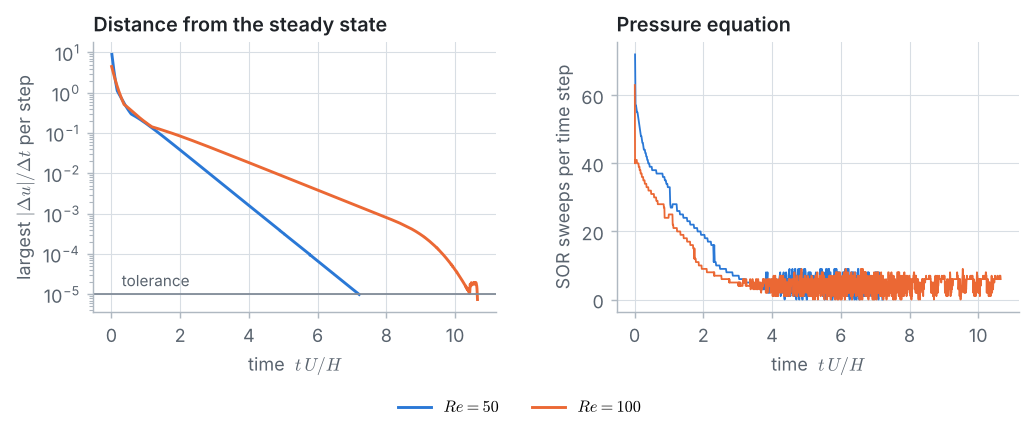

In [15]:
plots.history({Re: (solutions[Re][3], solutions[Re][4]) for Re in Re_values}, 1e-5)

The flow needs roughly one flow-through time ($t \approx L/U = 10$) to settle: the disturbance created by the sudden start is carried out through the outlet. At $Re = 50$ friction damps it on the way and the distance from the steady state falls steadily; at $Re = 100$ it decays more slowly and the last of it leaves through the outlet at $t \approx 10$, which is why the curve drops sharply there. At the start the pressure equation needs up to 70 sweeps per step; as the flow settles, the pressure of the previous step is an excellent first guess and about five sweeps are enough.

### Checking the whiteboard numbers

The whiteboard guide carries out **one projection step by hand** on a tiny channel: $2 \times 3$ cells of size $h = 1/3$ (so $L = 2/3$), $Re = 50$, $\Delta t = 0.01$, starting from plug flow. The cell below runs exactly the same three steps with the notebook's functions and prints every intermediate number. Rows are printed from the top ($j = 3$) down:

In [16]:
def show(name, field, rows, columns):
    """Print field[j][i] for the given rows (from the top down) and columns."""
    print(f"  {name}:")
    for j in reversed(rows):
        print(f"    j = {j}: " + "  ".join(f"{field[j][i] + 0.0:9.6f}" for i in columns))


Re_hand, nx_hand, ny_hand, dt_hand = 50, 2, 3, 0.01
h_hand = 1 / ny_hand
u_h, v_h, p_h = new_fields(nx_hand, ny_hand)
boundary_conditions(u_h, v_h, nx_hand, ny_hand)
us_h, vs_h = predictor(u_h, v_h, nx_hand, ny_hand, h_hand, dt_hand, Re_hand)
b_h = pressure_source(us_h, vs_h, nx_hand, ny_hand, h_hand, dt_hand)
sweeps_h = solve_pressure(p_h, b_h, nx_hand, ny_hand, 1e-13)
correct(u_h, v_h, us_h, vs_h, p_h, nx_hand, ny_hand, h_hand, dt_hand)

print("1 · predictor")
show("u* on the vertical faces (i = 0 inlet ... 2 outlet)", us_h, range(1, 4), range(0, 3))
print("2 · pressure equation")
show("b = h (flow out of the cell) / dt", b_h, range(1, 4), range(1, 3))
print(f"  pressure (SOR, {sweeps_h} sweeps):")
show("p", p_h, range(1, 4), range(1, 3))
print("3 · correction")
show("u", u_h, range(1, 4), range(0, 3))
show("v on the horizontal faces (j = 0 and 3 are the walls)", v_h, range(0, 4), range(1, 3))
div_h = divergence(u_h, v_h, nx_hand, ny_hand, h_hand)
print(f"largest |div u| after the step: {max(abs(d) for row in div_h for d in row):.1e}")
print(f"flow rate through the outlet: {h_hand * sum(u_h[j][nx_hand] for j in range(1, 4)):.6f}")

1 · predictor
  u* on the vertical faces (i = 0 inlet ... 2 outlet):
    j = 3:  1.000000   0.996400   0.996400
    j = 2:  1.000000   1.000000   1.000000
    j = 1:  1.000000   0.996400   0.996400
2 · pressure equation
  b = h (flow out of the cell) / dt:
    j = 3: -0.120000   0.000000
    j = 2:  0.000000   0.000000
    j = 1: -0.120000   0.000000
  pressure (SOR, 68 sweeps):
  p:
    j = 3:  0.130435   0.041739
    j = 2:  0.099130   0.036522
    j = 1:  0.130435   0.041739
3 · correction
  u:
    j = 3:  1.000000   0.999061   0.998904
    j = 2:  1.000000   1.001878   1.002191
    j = 1:  1.000000   0.999061   0.998904
  v on the horizontal faces (j = 0 and 3 are the walls):
    j = 3:  0.000000   0.000000
    j = 2: -0.000939  -0.000157
    j = 1:  0.000939   0.000157
    j = 0:  0.000000   0.000000
largest |div u| after the step: 7.0e-15
flow rate through the outlet: 1.000000


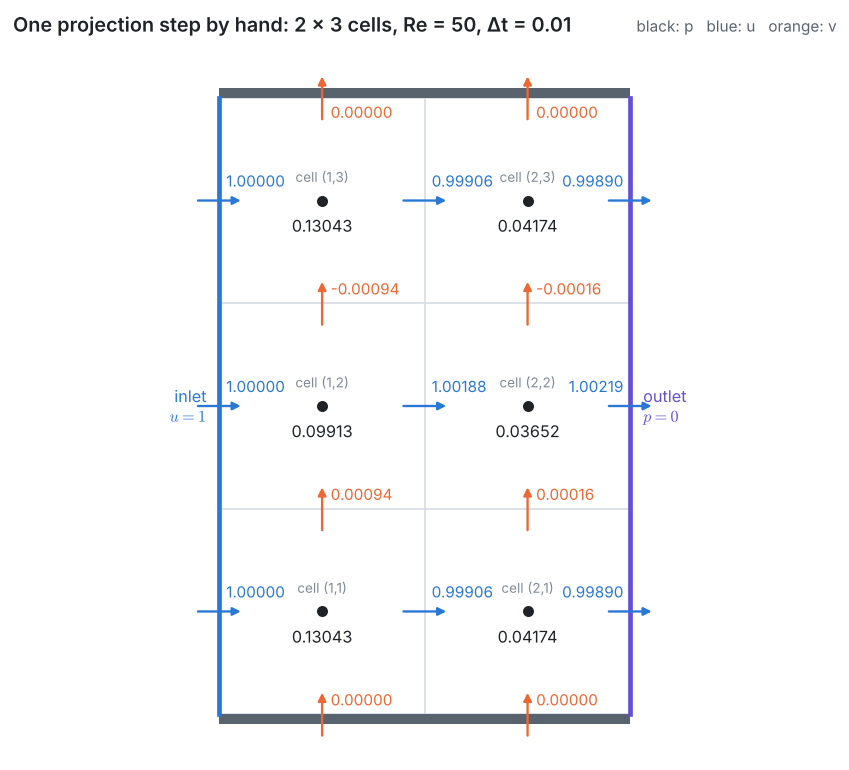

In [17]:
plots.hand_grid(u_h, v_h, p_h, "One projection step by hand: 2 × 3 cells, Re = 50, Δt = 0.01")

---
## Pillar 7 · Post-processing

### The velocity field

For the plots we need the velocities at the cell centres: the average of the two faces of each cell.

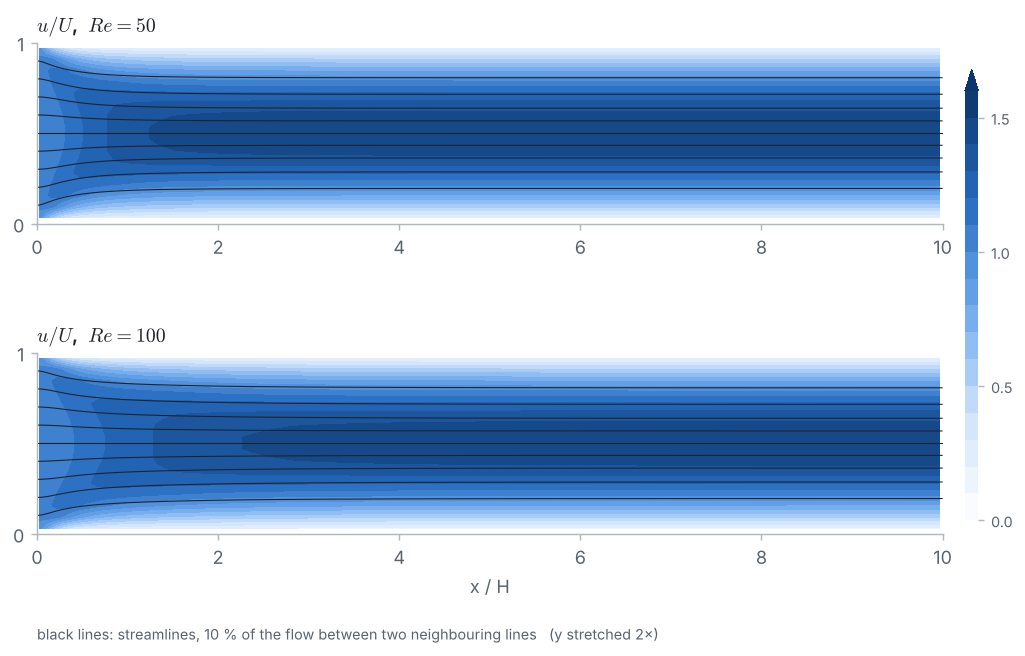

In [18]:
def cell_centres(u, nx, ny):
    """u averaged to the cell centres (for the colour map)."""
    return [[(u[j][i - 1] + u[j][i]) / 2 for i in range(1, nx + 1)] for j in range(1, ny + 1)]


def stream_function(u, nx, ny, h):
    """psi(x, y) = integral of u dy from the bottom wall, at the cell corners (for the streamlines)."""
    psi = [[0.0] * (nx + 1) for _ in range(ny + 1)]
    for j in range(1, ny + 1):
        for i in range(nx + 1):
            psi[j][i] = psi[j - 1][i] + u[j][i] * h
    return psi


xc = [(i - 0.5) * h for i in range(1, nx + 1)]     # cell centres
yc = [(j - 0.5) * h for j in range(1, ny + 1)]
x_faces = [i * h for i in range(nx + 1)]           # cell corners
y_faces = [j * h for j in range(ny + 1)]
plots.fields(xc, yc, x_faces, y_faces,
             {Re: (cell_centres(solutions[Re][0], nx, ny), stream_function(solutions[Re][0], nx, ny, h))
              for Re in Re_values}, length)

The fluid enters at $u = 1$ (white-blue). Near the walls it slows down at once; in the middle it accelerates until the centre reaches $u = 1.5$ (dark blue). At $Re = 100$ the inertia is twice as large compared with friction, and the development takes about twice as long. The black lines are **streamlines**, the contour lines of the stream function $\psi = \int_0^y u\,dy$ of Problem 6; between two neighbouring lines flows 10 % of the fluid. Near the inlet they bend **towards the centre**: the fluid pushed out of the slow wall layers moves to the middle ($v \neq 0$ in the entrance region). Further downstream they are straight and parallel ($v = 0$).

### Velocity profiles

$u(y)$ on several cross-sections, compared with the exact Poiseuille parabola:

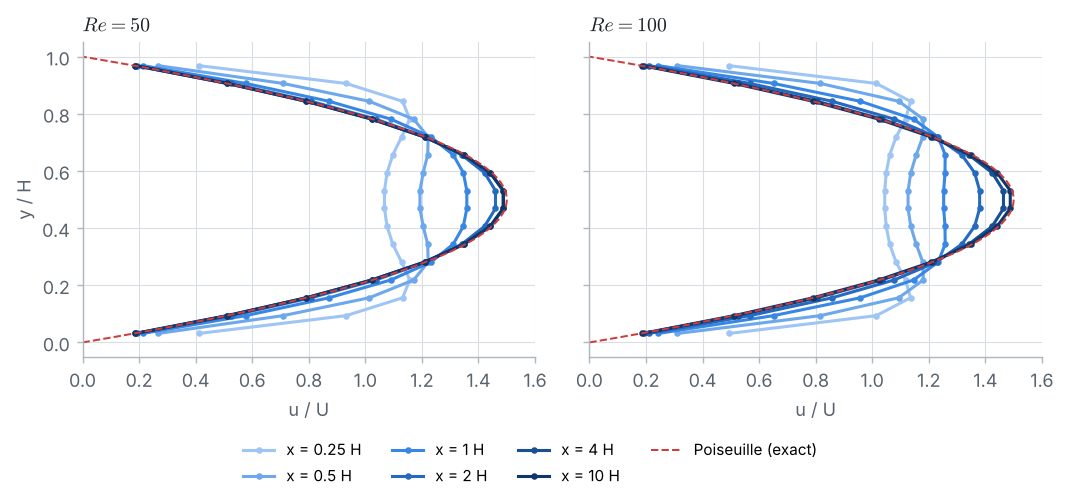

In [19]:
stations = [0.25, 0.5, 1, 2, 4, length]
cuts = {Re: {x: [solutions[Re][0][j][round(x / h)] for j in range(1, ny + 1)] for x in stations}
        for Re in Re_values}
plots.profiles(yc, cuts, poiseuille)

How close to Poiseuille flow can this grid get at all? The fully developed flow **on our grid** solves the discrete $x$-momentum equation with $v = 0$ and $\partial/\partial x = 0$: $(u_{j+1} - 2u_j + u_{j-1})/h^2 = Re\,dp/dx$, a constant, with the wall ghosts $u_0 = -u_1$ and $u_{n_y+1} = -u_{n_y}$, and a flow rate of 1. That is a tridiagonal system, one more job for the Thomas algorithm:

In [20]:
def developed_profile(ny, Re):
    """Fully developed flow on the grid: the discrete Poiseuille profile and its dp/dx."""
    h = 1 / ny
    below, diagonal, above = [1.0] * ny, [-2.0] * ny, [1.0] * ny
    below[0], above[-1] = 0.0, 0.0
    diagonal[0] = diagonal[-1] = -3.0              # ghost value u = -u beyond each wall
    shape = thomas(below, diagonal, above, [-1.0] * ny)   # u_{j+1} - 2 u_j + u_{j-1} = -1
    rate = h * sum(shape)
    profile = [s / rate for s in shape]            # scaled to a flow rate of 1
    dpdx = -1 / (Re * h * h * rate)
    return profile, dpdx


for Re in Re_values:
    profile, dpdx_grid = developed_profile(ny, Re)
    outlet = [solutions[Re][0][j][nx] for j in range(1, ny + 1)]
    error_exact = max(abs(outlet[k] - poiseuille(yc[k])) for k in range(ny))
    error_grid = max(abs(outlet[k] - profile[k]) for k in range(ny))
    print(f"Re = {Re:3d}: outlet profile minus exact Poiseuille: up to {error_exact:.4f};"
          f"  minus the grid's fully developed profile: up to {error_grid:.1e}")
profile, dpdx_grid = developed_profile(ny, 50)
centre = (profile[ny // 2 - 1] + profile[ny // 2]) / 2
print(f"fully developed flow on this grid: centre velocity {centre:.5f} (exact 1.5),"
      f"  Re dp/dx = {50 * dpdx_grid:.4f} (exact -12)")

Re =  50: outlet profile minus exact Poiseuille: up to 0.0058;  minus the grid's fully developed profile: up to 6.0e-06
Re = 100: outlet profile minus exact Poiseuille: up to 0.0061;  minus the grid's fully developed profile: up to 3.2e-04
fully developed flow on this grid: centre velocity 1.48837 (exact 1.5),  Re dp/dx = -11.9070 (exact -12)


Close to the inlet the profile is flat in the middle with steep sides, and it even has two small "ears" next to the walls (the fastest fluid is not yet in the centre). Downstream it turns into the parabola. At the outlet the numerical profile agrees with the grid's own fully developed flow to $6 \times 10^{-6}$ at $Re = 50$ and $3 \times 10^{-4}$ at $Re = 100$ (where the last tiny bit of development is still going on at $x = 10\,H$): the flow there has stopped developing. Its difference from the exact parabola, about 0.4 % of $u_{max}$, is the discretization error of the grid (mostly from the ghost-value wall condition, which is exact only for straight-line profiles), and it shrinks as $h^2$ in the grid study below.

### The entrance length

The centre line $y = 1/2$ lies between the rows $j = n_y/2$ and $n_y/2 + 1$, so we average the two. $L_e$ is where the centre-line velocity first reaches 99 % of its fully developed value (with linear interpolation between faces). As the fully developed value we take that of the grid's own fully developed flow (1.4884 on this grid, not exactly 1.5): this removes the small error the grid makes in the parabola itself, so that we measure only how far the flow has developed, and it does not depend on where the outlet is.

In [21]:
def centre_line(u, nx, ny):
    """u on the centre line y = 1/2 at every vertical face x = i h."""
    return [(u[ny // 2][i] + u[ny // 2 + 1][i]) / 2 for i in range(nx + 1)]


def entrance_length(line, h, developed):
    """Distance at which the centre-line velocity reaches 99 % of its fully developed value."""
    target = 0.99 * developed
    for i in range(1, len(line)):
        if line[i] >= target:
            return (i - 1 + (target - line[i - 1]) / (line[i] - line[i - 1])) * h


lines, L_e, developed = {}, {}, {}
for Re in Re_values:
    lines[Re] = centre_line(solutions[Re][0], nx, ny)
    profile, _ = developed_profile(ny, Re)
    developed[Re] = (profile[ny // 2 - 1] + profile[ny // 2]) / 2     # grid's Poiseuille centre
    L_e[Re] = entrance_length(lines[Re], h, developed[Re])
    difference = 100 * (L_e[Re] / durst(Re) - 1)
    print(f"Re = {Re:3d}: centre-line u at the outlet {lines[Re][-1]:.4f} (exact 1.5);"
          f"  L_e = {L_e[Re]:.3f} H,  Durst et al. {durst(Re):.3f} H  ({difference:+.1f} %)")

Re =  50: centre-line u at the outlet 1.4884 (exact 1.5);  L_e = 2.438 H,  Durst et al. 2.391 H  (+2.0 %)
Re = 100: centre-line u at the outlet 1.4880 (exact 1.5);  L_e = 4.669 H,  Durst et al. 4.542 H  (+2.8 %)


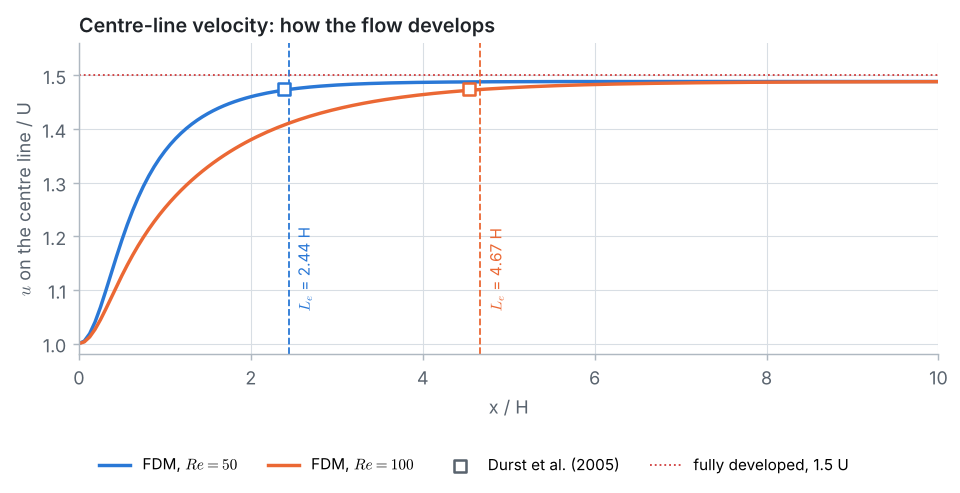

In [22]:
plots.centreline(x_faces, lines, L_e, {Re: durst(Re) for Re in Re_values}, developed)

The entrance length roughly doubles from $Re = 50$ to $Re = 100$, as the correlation predicts ($L_e \approx 0.044\,Re\,H$), and our values are 2–3 % longer than those of Durst et al. The grid study below shows how much of the difference is due to our grid. (We also checked that a longer channel, $L = 15\,H$, or a ten times tighter steady-state tolerance gives the same $L_e = 4.669\,H$ at $Re = 100$.)

### Mass conservation

What enters must leave. The flow rate through the cross-section at $x = i\,h$ is $Q = \sum_j u_{j,i}\,h$, and it should be 1 everywhere:

In [23]:
for Re in Re_values:
    u = solutions[Re][0]
    rates = [(x, h * sum(u[j][round(x / h)] for j in range(1, ny + 1)))
             for x in (0, 1, 2, 5, length)]
    div = divergence(u, solutions[Re][1], nx, ny, h)
    print(f"Re = {Re:3d}: flow rate " + ",  ".join(f"Q(x = {x:g}) = {q:.8f}" for x, q in rates))
    print(f"          largest |div u| in any cell: {max(abs(d) for row in div for d in row):.1e}")

Re =  50: flow rate Q(x = 0) = 1.00000000,  Q(x = 1) = 1.00000000,  Q(x = 2) = 1.00000000,  Q(x = 5) = 1.00000000,  Q(x = 10) = 1.00000000
          largest |div u| in any cell: 9.1e-07
Re = 100: flow rate Q(x = 0) = 1.00000000,  Q(x = 1) = 1.00000000,  Q(x = 2) = 1.00000000,  Q(x = 5) = 1.00000000,  Q(x = 10) = 1.00000000
          largest |div u| in any cell: 9.2e-07


The flow rate is 1 to eight decimals at every cross-section, and no cell gains or loses mass: the projection does exactly what it was built for.

### The pressure drop

The pressure on the centre line falls from the inlet to the outlet. Far downstream it falls along the straight line of Poiseuille flow, $dp/dx = -12/Re$. Near the inlet it falls **faster**: the pressure must also accelerate the fluid in the middle (from $u = 1$ to $1.5$), and the wall friction is larger where the boundary layers are thin. We extrapolate the centre-line pressure from the first two cells to $x = 0$ and split the total drop into the part a fully developed flow would need over the whole length, $|dp/dx|\,L$ (with the gradient computed at the outlet), and the **extra** drop caused by the entrance region, often written as $K\,\tfrac12\rho U^2$:

In [24]:
def centre_pressure(p, nx, ny):
    """p on the centre line at every cell centre x = (i - 1/2) h."""
    return [(p[ny // 2][i] + p[ny // 2 + 1][i]) / 2 for i in range(1, nx + 1)]


pressures, drops = {}, {}
for Re in Re_values:
    pc = centre_pressure(solutions[Re][2], nx, ny)
    p_inlet = 1.5 * pc[0] - 0.5 * pc[1]             # linear extrapolation to x = 0
    slope = (pc[-1] - pc[-2]) / h                    # dp/dx at the outlet
    pressures[Re] = [p_inlet] + pc + [0.0]
    drops[Re] = (p_inlet, slope)
    extra = p_inlet + slope * length
    print(f"Re = {Re:3d}: dp/dx at the outlet {slope:.4f} (exact {-12 / Re:.4f})")
    print(f"          inlet pressure {p_inlet:.4f} = {-slope * length:.4f} (fully developed)"
          f" + {extra:.4f} (extra),  K = {2 * extra:.3f}")

Re =  50: dp/dx at the outlet -0.2381 (exact -0.2400)
          inlet pressure 2.6139 = 2.3814 (fully developed) + 0.2325 (extra),  K = 0.465
Re = 100: dp/dx at the outlet -0.1191 (exact -0.1200)
          inlet pressure 1.4613 = 1.1906 (fully developed) + 0.2707 (extra),  K = 0.541


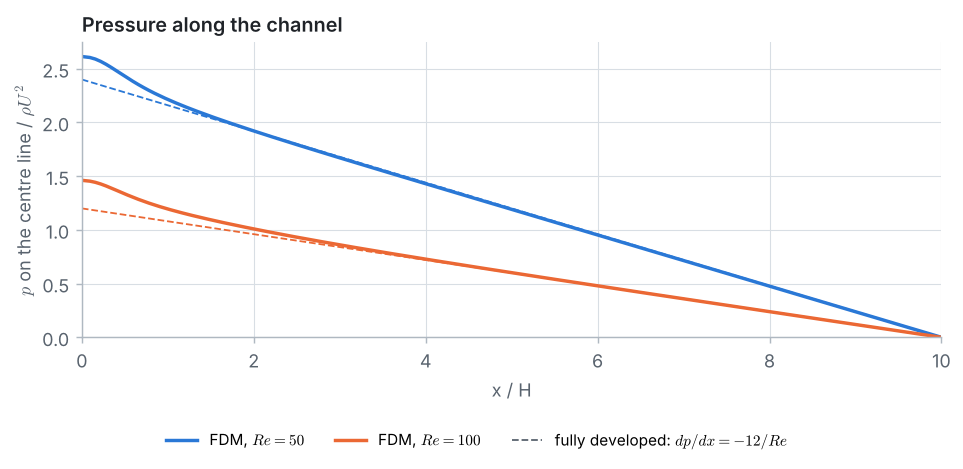

In [25]:
plots.pressure([0.0] + xc + [length], pressures, length)

The extra pressure drop of the entrance region is $0.23\,\rho U^2$ at $Re = 50$ and $0.27\,\rho U^2$ at $Re = 100$ ($K = 0.47$ and $0.54$): small compared with the 2.4 and 1.2 of the fully developed part over $10\,H$, but in a short channel it is the larger part. Its value is the least accurate number of this problem: the pressure is **singular at the inlet corners**, where the uniform inlet velocity meets the wall at rest (the corner cells in the figure of the checkerboard section below), and the grid study shows that the extra drop converges only slowly.

### Why the staggered grid? The checkerboard, with numbers

Take the converged pressure of $Re = 50$ and add a checkerboard, $\pm 0.1$ alternating from cell to cell. On a **collocated** grid the momentum equations see the pressure only through central differences, $(p_E - p_W)/(2h)$ and $(p_N - p_S)/(2h)$. On the **staggered** grid they see $(p_E - p_P)/h$ and $(p_N - p_P)/h$. Compare the two pressures through both:

In [26]:
amplitude = 0.1
p50 = solutions[50][2]
p_check = [[p50[j][i] + amplitude * (-1) ** (i + j) for i in range(nx + 2)] for j in range(ny + 2)]



def gradient_collocated(q, i, j):
    """Pressure gradient at the centre of cell (i, j) on a collocated grid."""
    return (q[j][i + 1] - q[j][i - 1]) / (2 * h), (q[j + 1][i] - q[j - 1][i]) / (2 * h)


def gradient_staggered(q, i, j):
    """Pressure gradient on the right and top faces of cell (i, j) on the staggered grid."""
    return (q[j][i + 1] - q[j][i]) / h, (q[j + 1][i] - q[j][i]) / h


largest = {}
for name, gradient in (("collocated", gradient_collocated), ("staggered", gradient_staggered)):
    largest[name] = max(abs(a - b) for j in range(2, ny) for i in range(2, nx)
                        for a, b in zip(gradient(p50, i, j), gradient(p_check, i, j)))

print(f"largest change of the pressure gradient caused by the checkerboard:")
print(f"  collocated grid, (p_E - p_W) / 2h:  {largest['collocated']:.1e}")
print(f"  staggered grid,  (p_E - p_P) / h:   {largest['staggered']:.2f}")

largest change of the pressure gradient caused by the checkerboard:
  collocated grid, (p_E - p_W) / 2h:  1.8e-15
  staggered grid,  (p_E - p_P) / h:   3.20


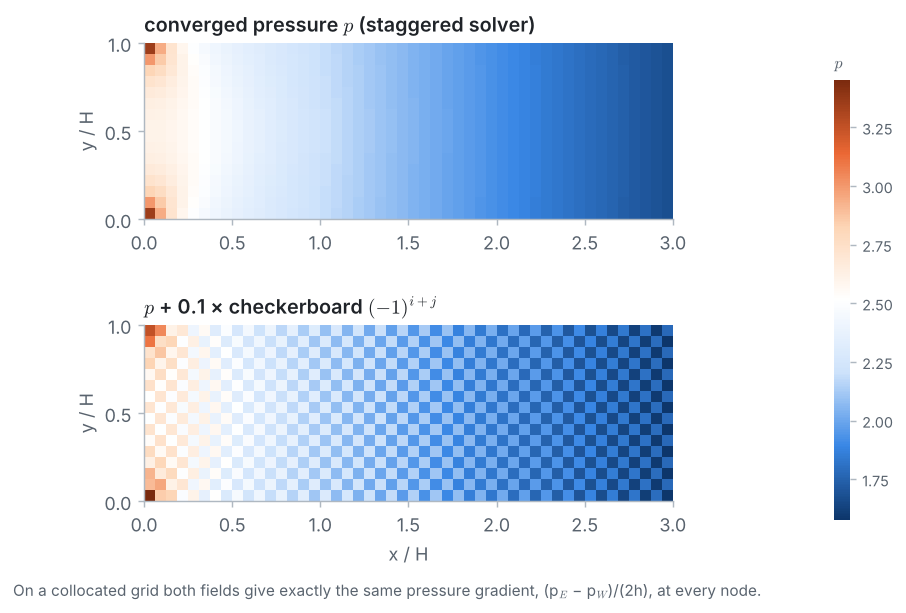

In [27]:
n3 = round(3 / h)                          # show the first 3 H of the channel
plots.checkerboard(xc[:n3], yc, [row[1:n3 + 1] for row in p50[1:ny + 1]],
                   [row[1:n3 + 1] for row in p_check[1:ny + 1]], amplitude)

On the collocated grid the checkerboard changes the pressure gradient by **nothing** (only round-off): $p_E$ and $p_W$ are always on the same colour of the board. So a collocated solver has no way to remove such a pattern once it appears, and the pressure equation built from the same central differences (a "wide" Laplacian linking only every second node) splits the grid into four independent sub-grids that drift apart. On the staggered grid the same checkerboard changes the gradient by $2 \times 0.1/h = 3.2$, the largest change any pattern of this size could make: it would be pushed away at once. (Collocated solvers do exist, but they need an extra fix, such as the Rhie–Chow interpolation of commercial finite volume codes, or the stabilisation used by COMSOL's finite elements.)

### Verification: grid study

We repeat the calculation for $Re = 50$ on three grids, $h = H/8$, $H/16$ and $H/32$. To keep the run time short we use a channel of length $5\,H$, twice the entrance length; we check below that this does not change the answer. **The finest grid takes about 75 seconds in plain Python.**

In [28]:
grids = [8, 16, 32]
short = 5.0
study = []
print("   h       steps  time [s]   L_e [H]   u_centre(outlet)   dp/dx (outlet)   extra drop")
for n in grids:
    start = time.time()
    u_n, v_n, p_n, hist_n, dt_n = solve_channel(50, short, n)
    nx_n = round(short * n)
    line = centre_line(u_n, nx_n, n)
    pc = centre_pressure(p_n, nx_n, n)
    profile, _ = developed_profile(n, 50)
    dpdx = (pc[-1] - pc[-2]) * n
    p_in = 1.5 * pc[0] - 0.5 * pc[1]
    result = {"Le": entrance_length(line, 1 / n, (profile[n // 2 - 1] + profile[n // 2]) / 2),
              "uc": line[-1], "dpdx": dpdx, "extra": p_in + dpdx * short}
    study.append(result)
    print(f"  1/{n:<3d} {len(hist_n):7d}  {time.time() - start:7.1f}   {result['Le']:7.4f}"
          f"       {result['uc']:.5f}          {result['dpdx']:.5f}       {result['extra']:.4f}")
print(f"  exact                                       1.50000          {-12 / 50:.5f}")
change = study[1]["Le"] - L_e[50]
print(f"  L = {length:g} H, h = 1/16:   L_e = {L_e[50]:.4f}")
print(f"  so the shorter channel changes L_e by {change:+.4f}")

   h       steps  time [s]   L_e [H]   u_centre(outlet)   dp/dx (outlet)   extra drop


  1/8       385      1.2    2.5008       1.45393          -0.23283       0.2497


  1/16      361      7.1    2.4384       1.48798          -0.23825       0.2318


  1/32      533     72.8    2.4327       1.49674          -0.23972       0.2231
  exact                                       1.50000          -0.24000
  L = 10 H, h = 1/16:   L_e = 2.4384
  so the shorter channel changes L_e by +0.0000


For a second-order scheme the error behaves like $C\,h^2$, and **Richardson extrapolation** (Problem 7) estimates the value on an infinitely fine grid from the two finest grids, $f \approx f_{h/2} + (f_{h/2} - f_h)/3$. Three grids give the observed order $p = \log_2\big[(f_{8} - f_{16})/(f_{16} - f_{32})\big]$:

In [29]:
print("                      h = 1/32   extrapolated   exact / correlation   observed order")
quantities = (("uc", "u_centre (outlet)", 1.5), ("dpdx", "dp/dx (outlet)", -12 / 50),
              ("Le", "entrance length", durst(50)), ("extra", "extra drop", None))
for name, label, reference in quantities:
    f8, f16, f32 = (s[name] for s in study)
    extrapolated = f32 + (f32 - f16) / 3
    order = math.log2((f8 - f16) / (f16 - f32))
    reference = f"{reference:8.4f}" if reference else "       -"
    print(f"  {label:18s}  {f32:8.4f}      {extrapolated:8.4f}         {reference}"
          f"            {order:.2f}")
L_e_extrapolated = study[2]["Le"] + (study[2]["Le"] - study[1]["Le"]) / 3

                      h = 1/32   extrapolated   exact / correlation   observed order
  u_centre (outlet)     1.4967        1.4997           1.5000            1.96
  dp/dx (outlet)       -0.2397       -0.2402          -0.2400            1.88
  entrance length       2.4327        2.4308           2.3915            3.45
  extra drop            0.2231        0.2202                -            1.05


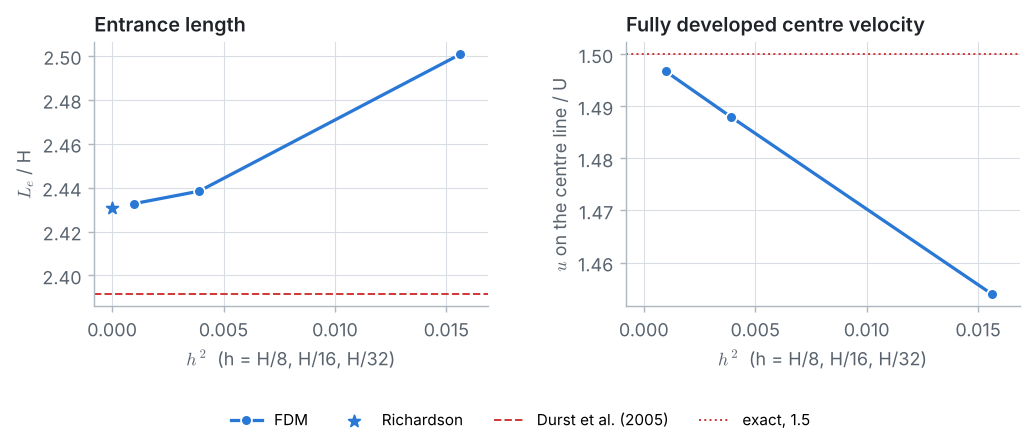

In [30]:
plots.grid_study([1 / n for n in grids], study, L_e_extrapolated, durst(50))

* The fully developed centre velocity and pressure gradient converge to the exact values $1.5$ and $-0.24$ with an observed order close to **2**, as expected from central differences; the extrapolated values agree with the exact ones to within 0.1 %.
* The entrance length converges too, to about $2.43\,H$. Its observed order is irregular, because $L_e$ is found by interpolating where a curve crosses the 99 % line, which adds a small error of its own; but the change from $h = H/16$ to $H/32$ is already below 0.3 %.
* The extra pressure drop converges only at **first order** (observed order 1.05), towards about $0.22\,\rho U^2$: the singular pressure at the inlet corners spoils the second order of the scheme there. A quantity taken from a singular point always needs a finer grid.
* Our grid-independent $L_e$ is about 1.6 % longer than the correlation of Durst et al. Such a small difference is within what different numerical studies report: the correlation is a fit, and the result depends a little on how the inlet is modelled (for example how the uniform inlet meets the wall at the corner).
* A channel of $5\,H$ gives the same entrance length as one of $10\,H$ (difference in the fourth decimal), so the outlet is far enough downstream.

---
## Summary

* For a flow **through** a domain we solve the Navier–Stokes equations for the **primitive variables** $u$, $v$, $p$. The pressure has no equation of its own: it is what keeps the velocity divergence-free.
* The **projection method** splits each time step into a predictor (momentum without pressure), a **pressure Poisson equation** and a correction that makes the velocity divergence-free. Marching in time until nothing changes gives the steady flow.
* On a **staggered (MAC) grid** the pressure sits in the cells and the velocities on the faces. Pressure differences across a face use neighbouring cells, so no checkerboard can hide in the pressure, as it can on a collocated grid.
* **Inlet and outlet conditions:** where the velocity is given (inlet, walls), the pressure is free ($\partial p/\partial n = 0$); where the pressure is given (outlet, $p = 0$), the velocity is free ($\partial u/\partial x = 0$).
* The pressure equation of a long channel is solved efficiently by SOR plus a **block correction** with the Thomas algorithm.
* The flow develops into **plane Poiseuille flow** ($u_{max} = 1.5\,U$, $dp/dx = -12\mu U/H^2$), the flow rate is conserved to eight decimals, and the entrance length ($2.43\,H$ at $Re = 50$, $4.67\,H$ at $Re = 100$) agrees with the correlation of Durst et al. (2005) to within 2–3 %.

## Try it yourself

1. Change `Re_values` to `[20, 200]`. Does $L_e$ still follow $0.044\,Re\,H$? (At $Re = 200$ use `length = 20`; why?)
2. Make the channel too short: `length = 3` at $Re = 100$. What happens to the outlet profile, and to $L_e$?
3. Replace the uniform inlet by the exact parabola, `u[j][0] = poiseuille((j - 0.5) * h)`. What should the solver return? (A fully developed flow from the start; the extra pressure drop disappears.)
4. Switch the block correction off (add `block=False` to the `solve_pressure` call in `solve_channel`) and time one run on the coarse grid, `solve_channel(50, 5, 8)`. How many times slower is it?
5. Set `omega = 1.0` (Gauss–Seidel) and `1.9` in `solve_pressure`. Which is fastest here?
6. *Challenge:* write the pressure equation of the collocated grid (the wide stencil $p_{i+2} - 2p_i + p_{i-2}$) and solve the channel with it. Do you see the checkerboard?